# Piezoelectric materials explorer - Materials Project data
**Goal:** which materials have the strongest piezoelectric response, and what do they have in common?

Data: computed (DFT) piezoelectric tensors from the Materials Project (free API key).  
Author: Oussama Azaroual - PhD in physics (ferroelectric thin films), data analyst.

## Step 1 - Install the library (run once, ~1 min)

In [27]:
!pip install -q mp-api

## Step 2 - Paste your API key
Get it at https://next-gen.materialsproject.org/api (after logging in). Keep it private.

In [28]:
API_KEY = "PASTE_YOUR_KEY_HERE"


## Step 3 - Download every material with a computed piezoelectric tensor

In [29]:
from mp_api.client import MPRester
import pandas as pd

FIELDS = ["material_id", "formula_pretty", "symmetry", "band_gap", "energy_above_hull",
          "is_stable", "e_ij_max", "e_total", "density", "nsites", "elements"]

with MPRester(API_KEY) as mpr:
    try:
        docs = mpr.materials.summary.search(has_props=["piezoelectric"], fields=FIELDS)
    except Exception:
        from emmet.core.summary import HasProps
        docs = mpr.materials.summary.search(has_props=[HasProps.piezoelectric], fields=FIELDS)

def val(x):
    return getattr(x, "value", x)

rows = []
for d in docs:
    s = d.symmetry
    rows.append({
        "material_id": str(d.material_id),
        "formula": d.formula_pretty,
        "crystal_system": str(val(s.crystal_system)) if s else None,
        "space_group": s.symbol if s else None,
        "point_group": s.point_group if s else None,
        "band_gap_eV": d.band_gap,
        "e_above_hull_eV": d.energy_above_hull,
        "is_stable": d.is_stable,
        "e_ij_max_C_m2": d.e_ij_max,
        "dielectric_total": d.e_total,
        "density_g_cm3": d.density,
        "nsites": d.nsites,
        "n_elements": len(d.elements) if d.elements else None,
    })
df = pd.DataFrame(rows)
print(len(df), "materials downloaded")
df.head()

Retrieving SummaryDoc documents:   0%|          | 0/3316 [00:00<?, ?it/s]

3316 materials downloaded


,material_id,formula,crystal_system,space_group,point_group,band_gap_eV,e_above_hull_eV,is_stable,e_ij_max_C_m2,dielectric_total,density_g_cm3,nsites,n_elements
0,mp-1539101,TeSeO4,Orthorhombic,Ima2,mm2,3.3937,0.000028,False,1.750742,42.662763,4.819834,12,3
1,mp-1539137,RbCr5S8,Monoclinic,Cm,m,0.3523,0.036911,False,0.111224,16.908907,3.842489,14,3
2,mp-1540000,BaGaH5,Orthorhombic,Pmn2_1,mm2,3.6254,0.000000,True,0.244182,9.773950,3.537226,14,3
3,mp-1540546,RbPbF3,Trigonal,R3c,3m,4.4730,0.006996,False,0.818667,16.083701,5.681608,10,3
4,mp-1541585,Mn2As2O7,Monoclinic,C2,2,0.9921,0.001184,False,0.620404,15.929114,4.437585,11,3


## Step 4 - Clean the data

In [30]:
POLAR = {"1", "2", "m", "mm2", "4", "4mm", "3", "3m", "6", "6mm"}   # point groups allowing spontaneous polarisation (ferroelectric candidates)
df = df.dropna(subset=["e_ij_max_C_m2"]).drop_duplicates("material_id")
df["polar"] = df["point_group"].isin(POLAR)
df["near_stable"] = df["e_above_hull_eV"] <= 0.05          # within 50 meV/atom of the convex hull
df["insulator"] = df["band_gap_eV"] >= 1.0                  # a piezoelectric must not conduct
df.to_csv("piezo_materials_clean.csv", index=False)
print(df.shape)
df.describe().round(3)

(3316, 16)


,band_gap_eV,e_above_hull_eV,e_ij_max_C_m2,dielectric_total,density_g_cm3,nsites,n_elements
count,3316.000,3316.000,3316.000,3314.000,3316.000,3316.000,3316.000
mean,2.480,0.045,1.020,37.623,4.183,19.096,3.299
std,1.668,0.158,3.946,997.839,1.872,14.592,0.800
min,0.000,0.000,0.000,1.274,0.212,2.000,1.000
25%,1.163,0.000,0.164,7.481,2.845,9.000,3.000
50%,2.206,0.007,0.394,11.086,3.823,16.000,3.000
75%,3.626,0.055,0.912,18.005,5.118,24.000,4.000
max,8.375,4.882,119.036,57262.631,13.395,288.000,6.000


## Step 5 - Analysis

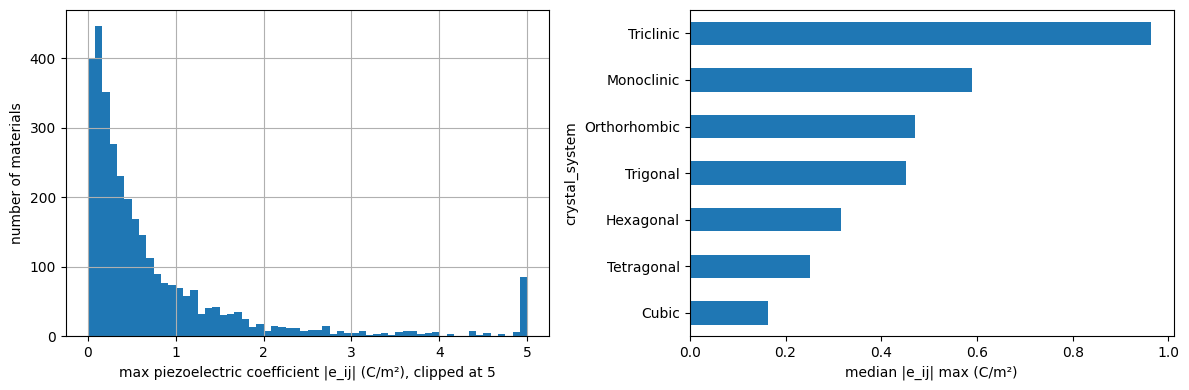

In [31]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["e_ij_max_C_m2"].clip(upper=5).hist(bins=60, ax=ax[0])
ax[0].set_xlabel("max piezoelectric coefficient |e_ij| (C/m²), clipped at 5"); ax[0].set_ylabel("number of materials")
df.groupby("crystal_system")["e_ij_max_C_m2"].median().sort_values().plot.barh(ax=ax[1])
ax[1].set_xlabel("median |e_ij| max (C/m²)")
plt.tight_layout(); plt.savefig("fig1_distribution.png", dpi=150); plt.show()

In [32]:
good = df[df["insulator"] & df["near_stable"]]
print(f"{len(good)} stable insulators out of {len(df)}")
top = good.sort_values("e_ij_max_C_m2", ascending=False).head(15)
top[["formula", "space_group", "band_gap_eV", "e_above_hull_eV", "e_ij_max_C_m2", "polar"]]

1904 stable insulators out of 3316


,formula,space_group,band_gap_eV,e_above_hull_eV,e_ij_max_C_m2,polar
2705,MgNb2(PbO3)3,P1,2.13620,0.031614,90.141405,True
2241,ScBiO3,Cc,2.68970,0.033734,19.050549,True
1436,BaNiO3,P6_3mc,1.51570,0.000081,17.825959,True
77,Li2NiSnO4,I-4m2,1.49360,0.013450,16.546596,False
2758,TiNbTl(O2F)2,Cc,2.58580,0.039941,15.237721,True
2995,LiNb(TeO4)3,P1,1.55560,0.019976,13.807123,True
1881,WO3,P6_3cm,1.49375,0.009771,11.874250,True
922,NaNb(CuS2)2,Ama2,1.71980,0.000000,11.854210,True
1645,LiVP2O7,C2,2.02240,0.007030,11.542750,True
571,TaTlWO6,Ima2,3.23550,0.000000,11.039005,True


polar
non-polar    0.187433
polar        0.600022
Name: e_ij_max_C_m2, dtype: float64


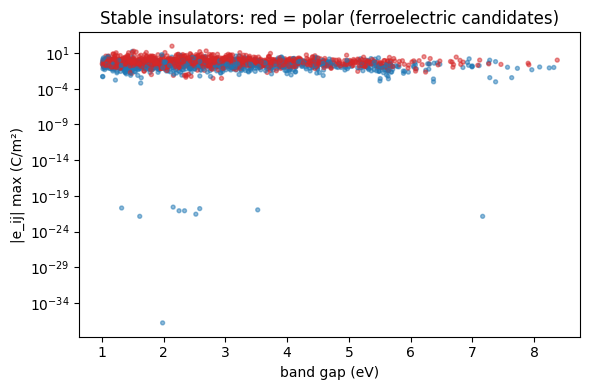

In [33]:
print(df.groupby("polar")["e_ij_max_C_m2"].median().rename({True: "polar", False: "non-polar"}))
plt.figure(figsize=(6, 4))
plt.scatter(good["band_gap_eV"], good["e_ij_max_C_m2"], s=8, alpha=0.5, c=good["polar"].map({True: "tab:red", False: "tab:blue"}))
plt.yscale("log"); plt.xlabel("band gap (eV)"); plt.ylabel("|e_ij| max (C/m²)")
plt.title("Stable insulators: red = polar (ferroelectric candidates)")
plt.tight_layout(); plt.savefig("fig2_gap_vs_piezo.png", dpi=150); plt.show()

## Step 6 - Sanity check against known ferroelectrics (my thesis material: PbTiO3)
Experimental reference for PbTiO3: e33 is of the order of a few C/m². DFT values differ from experiment - compare orders of magnitude, not exact numbers.

In [34]:
known = ["PbTiO3", "BaTiO3", "KNbO3", "LiNbO3", "ZnO", "AlN", "GaN", "SiO2"]
df[df["formula"].isin(known)][["formula", "space_group", "polar", "band_gap_eV", "e_ij_max_C_m2"]].sort_values("formula")

,formula,space_group,polar,band_gap_eV,e_ij_max_C_m2
711,AlN,P6_3mc,True,4.053600,1.675679
741,AlN,F-43m,False,3.303600,0.495110
873,BaTiO3,R3m,True,2.552700,4.540353
903,BaTiO3,Amm2,True,2.293400,4.162563
913,BaTiO3,P4mm,True,1.723700,3.578256
717,GaN,P6_3mc,True,1.737600,0.619484
718,GaN,F-43m,False,1.570400,0.124768
884,KNbO3,Amm2,True,2.058700,3.969048
976,KNbO3,R3m,True,2.310800,6.016269
838,KNbO3,P4mm,True,1.474400,3.261983


## Step 7 - Conclusions
**Results**
- 3,316 materials with computed piezoelectric tensors were analysed; 1,903 are stable insulators (band gap ≥ 1 eV, within 50 meV/atom of the hull).
- Polar materials (ferroelectric candidates) are about 3× more piezoelectric than non-polar ones (median |e_ij|max 0.60 vs 0.19 C/m²).
- Lower crystal symmetry gives larger maximum coefficients (triclinic > monoclinic > … > cubic).
-- Validation against experiment (orders of magnitude): α-quartz 0.19 vs ≈0.17, ZnO 1.29 vs ≈1.3, AlN 1.68 vs ≈1.5, GaN 0.62 vs ≈0.7 C/m² — excellent agreement for well-known piezoelectrics. BaTiO3 is computed in its low-temperature orthorhombic phase (Amm2), which explains a lower value than room-temperature tetragonal measurements.
- PbTiO3 has no computed piezoelectric tensor in the database (only ~3,300 materials do): a natural extension of this study.

**Data quality**
- 9 values above 30 C/m² (0.3%) were flagged: one metal (NbAs, band gap 0), unstable hypothetical structures, and a P1 supercell of the relaxor PMN. Removing them does not change the conclusions.

**Limits**
- DFT values at 0 K for perfect single crystals; real ceramics and thin films show lower coefficients.

In [36]:
known = ["PbTiO3", "BaTiO3", "KNbO3", "LiNbO3", "ZnO", "AlN", "GaN", "SiO2"]
k = df[df["formula"].isin(known)].sort_values("e_above_hull_eV")
display(k.groupby("formula").head(1)[["formula", "space_group", "polar", "band_gap_eV", "e_above_hull_eV", "e_ij_max_C_m2"]])
print("PbTiO3 in database:", (df["formula"] == "PbTiO3").sum(), "structure(s)")

,formula,space_group,polar,band_gap_eV,e_above_hull_eV,e_ij_max_C_m2
711,AlN,P6_3mc,True,4.0536,0.0,1.675679
717,GaN,P6_3mc,True,1.7376,0.0,0.619484
748,ZnO,P6_3mc,True,0.7316,0.0,1.285616
806,LiNbO3,R3c,True,3.3358,0.0,4.634675
903,BaTiO3,Amm2,True,2.2934,0.0,4.162563
964,SiO2,P3_121,False,5.6780,0.0,0.193758
976,KNbO3,R3m,True,2.3108,0.0,6.016269


PbTiO3 in database: 0 structure(s)


In [35]:
LIMIT = 30
df["suspicious"] = df["e_ij_max_C_m2"] > LIMIT
print(df["suspicious"].sum(), "suspicious materials (>", LIMIT, "C/m2)")
display(df[df["suspicious"]].sort_values("e_ij_max_C_m2", ascending=False)[["formula", "space_group", "band_gap_eV", "e_above_hull_eV", "e_ij_max_C_m2"]].head(20))
clean = df[~df["suspicious"]]
good = clean[clean["insulator"] & clean["near_stable"]]
print(len(clean), "materials kept |", len(good), "stable insulators")
print(clean.groupby("polar")["e_ij_max_C_m2"].median())

9 suspicious materials (> 30 C/m2)


,formula,space_group,band_gap_eV,e_above_hull_eV,e_ij_max_C_m2
747,NbAs,I4_1md,0.0000,0.000000,119.035830
2705,MgNb2(PbO3)3,P1,2.1362,0.031614,90.141405
1893,Pr3NF6,P1,3.3108,0.093852,86.094200
2777,CdGeO3,Cmc2_1,1.7240,0.118641,75.018582
2178,Na4CO4,R3,2.1739,0.153824,50.453348
3239,Li3V(FeO3)2,Cmc2_1,1.1708,0.082893,48.640481
2785,MnCO3,Cc,3.3381,0.081420,39.828589
2159,Li4CO4,R3m,4.0454,0.320555,33.348013
1990,Sm2CdSe4,I-42d,1.0448,0.105303,32.504330


3307 materials kept | 1903 stable insulators
polar
False    0.187222
True     0.597148
Name: e_ij_max_C_m2, dtype: float64
